# When does the AI coder pick its algorithm? An audit (demo of `eval.py`)

Ask Qwen3-8B to *"implement a path search algorithm"* and it nearly always writes **BFS** for an unweighted grid path
(task **T1**) and **Dijkstra** for a weighted shortest path (task **T2**). Six iteration-1 experiments then tried to
move it off that default:
- bans (*"do not use BFS"*), and sham bans of algorithms it never writes;
- temperature and top-k;
- context seeds (`seed=d32qxk4nt43`, `seed=(horse chair roof love)`);
- *"invent a fully novel algorithm"* instructions;
- activation steering;
- and, on the analysis side, probes and kNN-geodesic geometry on its residual stream.

This artifact is the **round-one audit** of those six experiments. It generates nothing, makes no LLM calls and costs
$0: it reads their saved outputs in place.

| Part | What it does | Stage script |
|---|---|---|
| 0a | re-runs the hidden-state **locus probe** that never ran: at which token and layer does the residual stream already say which algorithm will be written? | `locus.py` (GPU) |
| 0b | stress-tests the **activation-space geometry**: is the substitute the default's geodesic neighbour? It redraws the analysis on 1000 paraphrase subsamples | `geometry.py` |
| 0c | builds a cross-experiment **perturbation table**: 249 conditions, 20,270 programs | `tables.py` |
| 0d | **corrects the record**: per-draw substitutes, cumulative bans, a one-statistic **knob table**, PREDICT, BUY | `tables.py` |
| 0e–0h | seeds, missing outputs, sham-ban promotions, dated positioning | `tables.py`, web check |

**`eval.py` is the entry point.** It runs any stage script whose output is missing. It then assembles the stage outputs
into two files:
- `eval_out.json`: 80 headline metrics in `metrics_agg` plus four example datasets;
- `corrections.json`.

**This notebook is `eval.py` split into cells, with the code otherwise unchanged.** What differs:
- **File reads** become lookups in `data`. `mini_demo_data.json` holds every stage output `eval.py` reads, keyed by its
  original relative path (`results/locus.json`, `tables/knob_table.csv`, `exp3/forks.json`, …). The original read is
  kept as a comment on each replaced line.
- **The four row-level tables** are a curated **100-example subset**: 39 of 249 perturbation rows, 27 of 183 knob rows,
  20 of 903 probe cells and 14 of 56 geometry settings. The config cell caps how many are used.
- **Helpers.** The five helpers `eval.py` imports from the artifact's `common.py` are copied in.

**What is not re-run.** The stage scripts need 1.1 GB of iteration-1 inputs (the saved residual states) and a GPU,
about 16 minutes end to end. Their small outputs are what ship here.

The last section does three things:
- checks the recomputed `metrics_agg` against the published one;
- plots the activation space and the decision-locus curves;
- plots what the model writes under each perturbation, the knob table and the geometry.

The original module docstring:

```text
"""Round-one audit: when is the algorithm chosen?  Entry point.

Runs the stages that are missing (or all with --rerun) and assembles eval_out.json (exp_eval_sol_out) and
corrections.json from their outputs:
  inventory.py  (G2)       -> results/inventory.json
  locus.py      (0a, GPU)  -> results/locus.json, tables/locus_cells.csv
  geometry.py   (0b)       -> results/geometry.json, tables/geometry_stability.csv
  tables.py     (G3, 0c-0g)-> results/tables.json, results/harmonise.json, results/reference_map.json,
                              tables/perturbation_table.csv, tables/knob_table.csv
  results/positioning.json (0h, dated web check, written from logs/web/*.md)
  figures.py               -> figures/*.pdf|png
No generation, no LLM calls, no OpenRouter spend.

Usage: uv run eval.py [--rerun]
"""
```

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (the version eval.py was run with)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import argparse
import json
import math
import subprocess
import sys
import time

import numpy as np
import pandas as pd
from loguru import logger

# from common import HERE, RES, TAB, clean, jdump, setup_logging  # common.py is not part of the demo: its five helpers are copied below

# notebook additions: CSV tables arrive as text inside mini_demo_data.json; matplotlib for the figures
import io

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-2/evaluation-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["about"]["title"])
print("Files, keyed by the relative path eval.py reads them from:")
for name, content in data["files"].items():
    print(f"  {name:<32} " + (f"{len(content) - 1:>4} rows" if name.endswith(".csv") else f"{len(json.dumps(content)) // 1024:>4} KB"))
print(f"Curated subset ({data['about']['n_examples']} examples in all):")
for name, note in data["about"]["curation"].items():
    if name != "dropped_unread_keys":
        print(f"  {name}: {note}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Round-one audit: when does the AI coder pick its algorithm? (demo inputs for eval.py)
Files, keyed by the relative path eval.py reads them from:
  results/locus.json                155 KB
  results/geometry.json              14 KB
  results/tables.json                62 KB
  results/positioning.json            5 KB
  results/inventory.json              0 KB
  results/harmonise.json              0 KB
  results/figures.json                0 KB
  results/audit.json                  3 KB
  results/audit_extra.json            3 KB
  tables/perturbation_table.csv      39 rows
  tables/knob_table.csv              27 rows
  tables/locus_cells.csv             20 rows
  exp3/forks.json                     9 KB
Curated subset (100 examples in all):
  tables/perturbation_table.csv: 39 of 249 condition rows: all 29 perturbation types (bans, sham bans, temperature/top-k, context seeds, novelty instructions, steering,

## Config

`eval.py` has no iteration, epoch or sample-size knobs. It assembles numbers that its stage scripts already computed,
and even on the full tables that takes only seconds. What can be scaled is **how many rows of each stage-output
table go through the assembly**:

- `mini_demo_data.json` holds a curated subset; the original run used every row (see the comments).
- The first three geometry settings are the ones `geometry_section()` looks up by name, so `N_GEOMETRY_CELLS` must
  be at least 3.

The original command-line flag `--rerun` re-runs all seven stage scripts (about 16 minutes with a GPU). It has no
counterpart here, because the stage outputs come with the data.

In [5]:
# --- Config: how many rows of each stage-output table go through eval.py's assembly ---
# eval.py has no iterations/epochs/sample sizes: it assembles numbers its stage scripts already computed, so the
# assembly takes seconds at any size. These values use every row in mini_demo_data.json (100 examples).
N_PERTURBATION_ROWS = 39  # tables/perturbation_table.csv  (all 39 in the mini data; original run: 249; tested down to 2)
N_KNOB_ROWS = 27          # tables/knob_table.csv          (all 27 in the mini data; original run: 183; tested down to 2)
N_LOCUS_CELLS = 20        # tables/locus_cells.csv         (all 20 in the mini data; original run: 903; tested down to 2)
N_GEOMETRY_CELLS = 14     # results/geometry.json#grid     (all 14 in the mini data; original run: 56; minimum 3)

## Helpers from `common.py`

`eval.py` imports `HERE, RES, TAB, clean, jdump, setup_logging` from the artifact's `common.py`.
- They are copied below without change, except `HERE`: it becomes the notebook's working directory instead of the
  script's folder.
- The two outputs (`corrections.json`, `eval_out.json`) and the log file `logs/eval.log` are written to that directory.
- `RES` and `TAB` now appear only in `STAGES`. The files they used to name are read from `data`.

In [6]:
# --- from common.py: the names eval.py imports (HERE, RES, TAB, clean, jdump, setup_logging), copied as they are ---
from pathlib import Path
from typing import Any

HERE = Path.cwd()  # was: Path(__file__).resolve().parent -- outputs go to the notebook's working directory
RES = HERE / "results"
TAB = HERE / "tables"
LOG = HERE / "logs"


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOG / f"{name}.log", rotation="30 MB", level="DEBUG")


def jdump(obj: Any, p: Path) -> None:
    p.write_text(json.dumps(obj, indent=1, default=_json_default))


def _json_default(o: Any) -> Any:
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, set):
        return sorted(o)
    raise TypeError(f"not serialisable: {type(o)}")


def clean(o: Any) -> Any:
    """Recursively replace NaN/inf by None so the JSON is strict."""
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (float, np.floating)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.ndarray):
        return clean(o.tolist())
    if isinstance(o, np.bool_):
        return bool(o)
    return o

## Pipeline constants: `STAGES`, `VERDICT_CODE`, `run_stages()`, `fnum()`

- **`STAGES`** lists the seven stage scripts and the output file each one writes.
- **`VERDICT_CODE`** turns the locus verdict into a number for `metrics_agg`: 0 means no locus, 1 a post-commit
  readout, 2 a decision locus.
- **`run_stages()`** is how the full pipeline runs: it executes every stage whose output file is missing. It is kept
  here so the pipeline stays readable, but it is **not called**, because the stage outputs come from
  `mini_demo_data.json`.
- **`fnum()`** coerces a value to a finite float, or `None`.

In [7]:
STAGES = [("inventory", "inventory.py", RES / "inventory.json"), ("locus", "locus.py", RES / "locus.json"),
          ("geometry", "geometry.py", RES / "geometry.json"), ("tables", "tables.py", RES / "tables.json"),
          ("figures", "figures.py", RES / "figures.json"), ("audit", "audit.py", RES / "audit.json"),
          ("audit_extra", "audit_extra.py", RES / "audit_extra.json")]
VERDICT_CODE = {"R (no candidate passed the 20-point rule)": 0, "NOT PASSING": 0, "POST-COMMIT READOUT": 1,
                "DECISION LOCUS": 2}


def run_stages(rerun: bool) -> dict:
    timing = {}
    for name, script, out in STAGES:
        if out.exists() and not rerun:
            logger.info(f"stage {name}: output present, skipped")
            continue
        t0 = time.time()
        logger.info(f"stage {name}: running {script}")
        subprocess.run([sys.executable, str(HERE / script)], check=True, cwd=HERE)
        timing[name] = time.time() - t0
    return timing


def fnum(x) -> float | None:
    try:
        v = float(x)
    except (TypeError, ValueError):
        return None
    return v if math.isfinite(v) else None

## 0a: `locus_section()` — when does the residual stream know which algorithm it will write?

`locus.py` fitted probes on Qwen3-8B residual states that exp3 saved: 2 tasks × 300 generations × 8 token positions ×
layers 8–28. The probes are leave-one-paraphrase-out L2-logistic, solved by a batched IRLS solver in torch.

**Token positions.**
- `R`: the end of the prompt.
- `k8`…`k64`: generated tokens 8 to 64.
- `k_pre` / `k_post`: the tokens just before and just after the commit token, where the program first shows its
  algorithm.
- `k_fork`: exp3's forking token. It has states on T2 only.

**Contrasts.**
- **W** (within the ban arm, same prompts): can the state tell which algorithm the model will write? On T1 this is
  DFS vs BFS; on T2, BF/SPFA vs Dijkstra.
- **P1/P2**: positive controls (ban prompt vs baseline prompt).

`locus_section()` flattens each W position at its best layer `L*`. For each it reports:
- the balanced accuracy (BA);
- the layer-max permutation nulls. The 200 *global* shuffles test for any signal. The 200 *within-paraphrase*
  shuffles ask whether the signal is about the individual sample or only about which paraphrase was asked.
- the **written-text control** `BA_text`: the same kind of probe, run on the generated tokens alone;
- the difference-in-means (DiM) AUC.

It also reports the verdict of the **20-point rule**, which walks the positions in order of token index:
- A position *passes* when its BA at `L*` beats `R` at the same layer by **≥ 0.20** and also beats both layer-max
  null p95s. The first position that passes is the `mechanical_locus`; if none passes, the verdict is `R`.
- It is a **DECISION LOCUS** only if it is also pre-commit and beats the written text by **≥ 0.10**. Otherwise it is a
  **POST-COMMIT READOUT**: the state merely reads off what is already written.

`flat` holds the locus entries of `metrics_agg`. The `extraction_target` strings are the authors' write-up of these
same numbers.

In [8]:
def locus_section(loc: dict) -> tuple[dict, dict]:
    sec = {"failure_cause": loc["failure_cause"], "device": loc["device"], "dtype": loc["dtype"],
           "solver_unit_test": {t: {"passed": u["passed"], "max_rel_coef_diff": u["max_rel_coef_diff"],
                                    "n_checks": len(u["checks"]),
                                    "max_rel_coef_diff_vs_sklearn_default_tol": max(c["rel_coef_diff_vs_default_tol"] for c in u["checks"])}
                                for t, u in loc["unit_test"].items()},
           "design": ("contrast W = within-ban same prompts (T1 G2 DFS=1 vs BFS=0, unit_dijkstra excluded; T2 G2 BF_SPFA=1 vs "
                      "DIJKSTRA=0); P1 baseline-default vs ban-default; P2 baseline-default vs ban-substitute. LOPO 10 folds; "
                      "in-fold StandardScaler + PCA(64); L2 logistic, balanced class weights, unpenalised intercept, C in "
                      "{0.01,0.1,1} by inner GroupKFold(3) pooled log-loss; batched Newton-IRLS in torch (float32 on GPU). "
                      "Nulls: 200 global + 200 within-paraphrase refits for W (same permutation vectors at every layer of a "
                      "position), 50 global for P1/P2."),
           "timing_s": loc["timing"], "tasks": {}}
    flat = {}
    for t, T in loc["tasks"].items():
        W = T["contrasts"]["W"]["positions"]
        lm = {}
        for p, pr in W.items():
            li = pr["layers"].index(pr["L_star"])
            lm[p] = {"n": pr["n"], "n_min": pr["n_min"], "median_k": pr["median_k"], "L_star": pr["L_star"],
                     "layer_max_BA": pr["layer_max_BA"], "BA_ci_at_L_star": pr["BA_ci"][li], "AUC_at_L_star": pr["AUC"][li],
                     "CE_bits_at_L_star": pr["CE_bits"][li], "IG_bits_at_L_star": pr["IG_bits"][li],
                     "C_chosen_at_L_star": pr["C_chosen"][li], "null_global_p95": pr["layer_max_null_global_p95"],
                     "null_within_p95": pr["layer_max_null_within_p95"], "p_layermax_global": pr["p_layermax_global"],
                     "p_layermax_within": pr["p_layermax_within"], "n_precommit": pr["n_precommit"],
                     "precommit_class_counts": pr["precommit_class_counts"],
                     "precommit_layer_max_BA": pr.get("precommit_layer_max_BA"),
                     "BA_text": T["text"]["per_position"].get(p, {}).get("BA_text"),
                     "DiM_AUC_at_L_star": pr["DiM_AUC"][li], "DiM_AUC_ci": pr["DiM_AUC_ci"][li]}
        curve = {k: v["BA_text"] for k, v in T["text"]["curve"].items()}
        ks = sorted(int(k) for k in curve)
        first_reveal = next((k for k in ks if curve[str(k)] >= 0.6), None)
        rule = T["rule"]
        mech = rule["mechanical_locus"]
        qual = rule["qualified_verdict"]
        if t == "T2":
            target = ("The written prefix first separates the classes at k=4 (BA_text 0.762 on tokens 0..3: Dijkstra rows "
                      "write '```python\\nimport' then ' heapq'; BF_SPFA rows write '```python\\nfrom collections import' then "
                      "' deque'), so the deciding token is generated index 3 and it is emitted from the state at k=3 (absolute "
                      "index prompt_len+2). States k=1..3 are unsaved: extract them in the next round's GPU step. exp3's own "
                      "resampling fork screen independently confirmed forks at generated index 3 ('import', TVD 0.80 and "
                      "0.77; exp3/forks.json T2|ban|0 and T2|ban|1). The literal rule (first k with BA_text >= 0.8) gives "
                      f"k={T['text']['first_k_BA_text_ge_0.8']}.")
        else:
            target = ("No prefix up to k=64 reaches BA_text 0.8 (max 0.673 at k=7..16): DFS and BFS rows share the commit "
                      "token (' deque' for 55/78 DFS and 21/21 BFS rows), so the AST commit index does not separate the classes "
                      "on T1 and the within-ban signal at every saved position is paraphrase-level (within-paraphrase null "
                      "p95 >= observed). Extraction target: per-row first token where DFS and BFS code diverge (beyond k=64, "
                      "e.g. pop vs popleft), plus k=1..7.")
        sec["tasks"][t] = {"counts": T["counts"], "commit_idx_distribution": T["commit_idx_distribution"],
                           "pool_join": T["pool_join"], "position_order": rule["position_order"],
                           "positions_unavailable": T["contrasts"]["W"].get("positions_unavailable", {}),
                           "layer_max_table": lm, "rule_trace": rule["trace"], "mechanical_locus": mech,
                           "qualified_verdict": qual, "decision_locus_positions": rule["decision_locus_positions"],
                           "power_note": rule["power_note"], "use_for_next_round": rule["use_for_next_round"],
                           "text_locus_curve": curve, "text_first_k_BA_ge_0.8": T["text"]["first_k_BA_text_ge_0.8"],
                           "text_first_k_BA_ge_0.6": first_reveal, "extraction_target": target,
                           "decoded_prefixes": T["text"].get("decoded_prefixes"),
                           "token_strings_first12": T["text"].get("token_strings_first12"),
                           "dim": T["dim"], "commit_aligned_curve": T["commit_aligned_curve"],
                           "R_compliance_preview": T["R_compliance_preview"],
                           "pca_views_explained": {k: v["explained"] for k, v in T["pca_views"].items()},
                           "positive_controls": {c: {p: {"layer_max_BA": pr["layer_max_BA"], "L_star": pr["L_star"],
                                                         "p_layermax_global": pr["p_layermax_global"], "n": pr["n"]}
                                                     for p, pr in T["contrasts"][c]["positions"].items()} for c in ("P1", "P2")},
                           "layer_convention": T["layer_convention"]}
        kp = W["k_pre"]
        kli = kp["layers"].index(kp["L_star"])
        trace = {r["position"]: r for r in rule["trace"]}
        flat.update({f"locus_{t}_BA_kpre": kp["layer_max_BA"], f"locus_{t}_Lstar_kpre": kp["L_star"],
                     f"locus_{t}_delta_vs_R_kpre": trace["k_pre"]["delta_vs_R"],
                     f"locus_{t}_BA_R": W["R"]["layer_max_BA"], f"locus_{t}_BA_k8": W["k8"]["layer_max_BA"],
                     f"locus_{t}_BA_text_kpre": T["text"]["per_position"]["k_pre"]["BA_text"],
                     f"locus_{t}_p_within_kpre": kp["p_layermax_within"],
                     f"locus_{t}_verdict_mechanical_is_R": 1.0 if mech == "R" else 0.0,
                     f"locus_{t}_verdict_code": VERDICT_CODE.get(qual, 0),
                     f"locus_{t}_n_decision_locus_positions": len(rule["decision_locus_positions"]),
                     f"text_locus_{t}_first_k_ge_0p8": T["text"]["first_k_BA_text_ge_0.8"] or -1,
                     f"text_locus_{t}_first_k_ge_0p6": first_reveal or -1,
                     f"dim_auc_{t}_kpre": T["dim"]["k_pre"]["DiM_AUC_at_L_star"],
                     f"dim_auc_{t}_R": T["dim"]["R"]["DiM_AUC_at_L_star"],
                     f"dim_auc_{t}_k8": T["dim"]["k8"]["DiM_AUC_at_L_star"],
                     f"R_compliance_{t}_spearman": T["R_compliance_preview"]["spearman_rho"],
                     f"R_compliance_{t}_exact_p": T["R_compliance_preview"]["exact_perm_p"]})
        flat[f"locus_{t}_delta_vs_R_mech"] = trace[mech]["delta_vs_R"] if mech in trace else 0.0
    return sec, flat

## exp3 forking tokens: `fork_thresholds()`

exp3 resampled continuations from each prefix position. It flagged **forking tokens**: positions where the
distribution over the algorithm finally written jumps, measured as total variation distance (TVD).

`fork_thresholds()` counts how many candidates stay confirmed as the TVD threshold rises from 0.10 to 0.30. The T2
forks sit at generated index 3 (`import`, TVD 0.80), which is where the written text starts to separate the classes.

The one change: `exp3/forks.json` is read from `data`.

In [9]:
def fork_thresholds() -> dict:
    """exp3 fork confirmation-threshold sensitivity (TVD 0.10/0.15/0.20/0.30) from exp3/forks.json."""
    # from common import EXP
    # d = json.loads((EXP["exp3"] / "forks.json").read_text())
    d = data["files"]["exp3/forks.json"]  # notebook: exp3/forks.json ships inside mini_demo_data.json
    cands = []
    for c in d.get("forks", []):
        cands.append({k: c.get(k) for k in ("bp_id", "task", "condition", "t", "token", "tvd", "p_perm", "commit_idx",
                                            "confirmed_tvd0.10", "confirmed_tvd0.15", "confirmed_tvd0.20", "confirmed_tvd0.30",
                                            "confirmed")})
    summ = {}
    for th in ("0.10", "0.15", "0.20", "0.30"):
        for t in ("T1", "T2"):
            summ[f"{t}_confirmed_at_tvd{th}"] = sum(1 for c in cands if c["task"] == t and c.get(f"confirmed_tvd{th}"))
    return {"candidates": cands, "summary": summ, "source": "exp3/forks.json#forks"}

## 0b: `geometry_section()` — is the substitute the default's neighbour in activation space?

**exp2's claim.** Ban the default, and the model writes the algorithm whose centroid lies geodesically closest to the
default's centroid. Distances run along a kNN graph over PCA-reduced residual states of prompts that force each
algorithm.

**What `geometry.py` did.**
1. It reproduced exp2's committed distance matrices exactly.
2. It rebuilt PCA, graph and centroids **1000 times on paraphrase subsamples** (24 of 30 paraphrases), at every
   setting of (layer, k = number of kNN neighbours).

`geometry_section()` pulls three things:
- the headline settings: T2 layer 24 and T1 layer 27, k = 5–20;
- the masked-prompt sensitivity;
- the flat metrics. `P_X_nearest` is the share of the 1000 subsamples in which algorithm X is the survivor nearest to
  the default.

In [10]:
def geometry_section(g: dict) -> tuple[dict, dict]:
    grid = [c for c in g["grid"]]
    head = {}
    for c in grid:
        if c["kind"] == "forced" and ((c["task"] == "t2" and c["layer"] == 24) or (c["task"] == "t1" and c["layer"] == 27)):
            head[f"{c['task']}_L{c['layer']}_k{c['k']}"] = {k: v for k, v in c.items() if k not in ("task", "layer", "k", "kind")}
    sens = g["reproduce"]["t2"]["sensitivity"]
    sec = {"reproduce": g["reproduce"], "headline_settings": head, "across_settings": g["across_settings"],
           "masked_sensitivity": [{k: c[k] for k in ("task", "layer", "k", "full_order", "share_nearest", "top1_stability")}
                                  for c in grid if c["kind"] == "masked"],
           "sensitivity_matrix_T2_dijkstra_row": sens["dijkstra_row_named"], "nearest_survivor_sensitivity": sens["nearest_survivor"],
           "wording": g["wording"], "table": "tables/geometry_stability.csv", "figure": "figures/fig_geometry_heatmap.pdf",
           "resampling": "1000 draws of 24 of 30 paraphrase ids without replacement, same ids for every mode; PCA, graph and centroids rebuilt per draw"}
    t2 = next(c for c in grid if c["task"] == "t2" and c["layer"] == 24 and c["k"] == 10 and c["kind"] == "forced")
    t1 = next(c for c in grid if c["task"] == "t1" and c["layer"] == 27 and c["k"] == 10 and c["kind"] == "forced")
    t1_24 = next(c for c in grid if c["task"] == "t1" and c["layer"] == 24 and c["k"] == 10 and c["kind"] == "forced")
    t2f = [c for c in grid if c["task"] == "t2" and c["kind"] == "forced"]
    flat = {"geo_T2_P_BF_nearest_L24_k10": t2["P_BF_SPFA_nearest"], "geo_T2_P_FW_nearest_L24_k10": t2["P_FW_nearest"],
            "geo_T2_P_BF_nearer_than_BIDIR_L24_k10": t2["P_BF_SPFA_nearer_than_BIDIR_DIJKSTRA"],
            "geo_T2_min_P_FW_nearest_all_settings": min(c["P_FW_nearest"] for c in t2f),
            "geo_T2_max_P_BF_nearest_all_settings": max(c["P_BF_SPFA_nearest"] for c in t2f),
            "geo_T1_P_DFS_nearest_L27_k10": t1["P_DFS_nearest"], "geo_T1_P_DFS_nearest_L24_k10": t1_24["P_DFS_nearest"],
            "geo_T1_P_DFS_UNITDIJ_two_nearest_L27_k10": t1["P_DFS_UNIT_DIJKSTRA_two_nearest"],
            "geo_T1_kendall_tau_mean": g["across_settings"]["t1"]["kendall_tau_b_mean"],
            "geo_T2_kendall_tau_mean": g["across_settings"]["t2"]["kendall_tau_b_mean"],
            "geo_T1_share_settings_realised_rank1": g["across_settings"]["t1"]["share_settings_realised_rank"]["1"],
            "geo_T2_share_settings_realised_rank1": g["across_settings"]["t2"]["share_settings_realised_rank"]["1"],
            "geo_T2_kruskal_stress_L24_k10": t2["kruskal_stress1_mds2"], "geo_T1_kruskal_stress_L27_k10": t1["kruskal_stress1_mds2"],
            "geo_reproduce_max_abs_diff": max(g["reproduce"]["t1"]["max_abs_diff"], g["reproduce"]["t2"]["max_abs_diff"],
                                              sens["max_abs_diff"])}
    return sec, flat

## `examples_from_tables()`: one example per table row

This function turns every row of the four tables into one `exp_eval_sol_out` example:
- `input`: the condition;
- `output`: the composition of correct programs, the probe BA, or the geometry order;
- `predict_*`: the comparison targets;
- `eval_*`: the numeric fields.

Together they form the `datasets` block of `eval_out.json`: `perturbation_table`, `locus_cells`, `knob_table` and
`geometry_grid`.

In [11]:
def examples_from_tables(pt: pd.DataFrame, kt: pd.DataFrame, cells: pd.DataFrame, geo: dict) -> list[dict]:
    def ev(d: dict) -> dict:
        return {k: v for k, v in d.items() if v is not None}

    ds = []
    ex = []
    for _, r in pt.iterrows():
        e = {"input": f"{r.experiment}|{r.task}|{r.condition} (type={r.type}; reference={r.reference or 'none'}; engine={r.engine})",
             "output": str(r.composition_correct),
             "predict_runner_up_share_correct": "" if pd.isna(r.runner_up_share_correct) else f"{r.runner_up_share_correct:.4f} {r.runner_up_ci_correct}",
             "predict_default_share_correct": "" if pd.isna(r.default_share_correct) else f"{r.default_share_correct:.4f} {r.default_ci_correct}",
             "metadata_source": r.source, "metadata_composition_attempted": str(r.composition_attempted),
             "metadata_type": r.type}
        e.update(ev({"eval_N": fnum(r.N), "eval_attempted": fnum(r.attempted), "eval_correct": fnum(r.correct),
                     "eval_pass_rate": fnum(r.pass_rate), "eval_pass_cost_pts": fnum(r.get("pass_cost_pts")),
                     "eval_pass_cost_ci_lo": fnum(r.get("pass_cost_ci_lo")), "eval_pass_cost_ci_hi": fnum(r.get("pass_cost_ci_hi")),
                     "eval_runner_up_share_correct": fnum(r.runner_up_share_correct),
                     "eval_runner_up_share_attempted": fnum(r.runner_up_share_attempted),
                     "eval_default_share_correct": fnum(r.default_share_correct),
                     "eval_n_distinct_labels": fnum(r.n_distinct_labels_attempted),
                     "eval_runtime_vs_ast_disagree": fnum(r.runtime_vs_ast_disagree)}))
        ex.append(e)
    ds.append({"dataset": "perturbation_table", "examples": ex})
    ex = []
    for _, r in cells.iterrows():
        e = {"input": f"{r.task}|{r.contrast}|{r.position}|layer {int(r.layer)}",
             "output": f"BA={r.BA:.4f} [{r.CI_lo:.3f},{r.CI_hi:.3f}] n={int(r.n)} n_min={int(r.n_min)}",
             "predict_probe_label": "substitute (1) vs default (0)" if r.contrast == "W" else "ban (1) vs baseline (0)",
             "metadata_C_chosen": str(r.C_chosen)}
        e.update(ev({"eval_BA": fnum(r.BA), "eval_BA_ci_lo": fnum(r.CI_lo), "eval_BA_ci_hi": fnum(r.CI_hi), "eval_AUC": fnum(r.AUC),
                     "eval_CE_bits": fnum(r.CE_bits), "eval_IG_bits": fnum(r.IG), "eval_p_global": fnum(r.p_global),
                     "eval_p_within": fnum(r.p_within), "eval_BA_text": fnum(r.BA_text),
                     "eval_BA_precommit": fnum(r.BA_precommit), "eval_n_precommit": fnum(r.n_precommit),
                     "eval_n": fnum(r.n), "eval_DiM_AUC": fnum(r.DiM_AUC)}))
        ex.append(e)
    ds.append({"dataset": "locus_cells", "examples": ex})
    ex = []
    for _, r in kt.iterrows():
        e = {"input": f"{r.task}|{r.knob} (type={r.type}; class={r.knob_class})",
             "output": str(r.compliant_composition),
             "predict_positive_target": str(bool(r.positive_target)),
             "metadata_below_depth": str(bool(r.below_depth)), "metadata_ci90": str(r.get("hill1_ci90"))}
        e.update(ev({"eval_hill1_rarefied_d25": fnum(r.hill1_rarefied), "eval_n_compliant": fnum(r.n_compliant),
                     "eval_pass_points": fnum(r.pass_points), "eval_hill1_plugin": fnum(r.hill1_plugin_compliant)}))
        ex.append(e)
    ds.append({"dataset": "knob_table", "examples": ex})
    ex = []
    for c in geo["grid"]:
        e = {"input": f"{c['task'].upper()}|{c['kind']}|layer {c['layer']}|k={c['k']}",
             "output": ">".join(c["full_order"]), "predict_nearest_survivor": c["full_order"][0],
             "metadata_share_nearest": json.dumps(c["share_nearest"])}
        vals = {"eval_top1_stability": c["top1_stability"], "eval_realised_rank": c["realised_substitute_rank_full"],
                "eval_kruskal_stress1": c.get("kruskal_stress1_mds2"), "eval_mst_added_share": c["mst_added_share"],
                "eval_geodesic_euclid_agree_share": c["geodesic_euclid_agree_share"]}
        for k in ("P_BF_SPFA_nearest", "P_FW_nearest", "P_BF_SPFA_nearer_than_BIDIR_DIJKSTRA", "P_DFS_nearest",
                  "P_UNIT_DIJKSTRA_nearest", "P_DFS_UNIT_DIJKSTRA_two_nearest"):
            if k in c:
                vals[f"eval_{k}"] = c[k]
        e.update(ev({k: fnum(v) for k, v in vals.items()}))
        ex.append(e)
    ds.append({"dataset": "geometry_grid", "examples": ex})
    return ds

## `main()`, step 1: load the stage outputs

The body of `main()` is split over the next seven cells, dedented to top level and otherwise unchanged.
- Each file read becomes a lookup in `data`, with the original read kept as a comment.
- The config cell caps the rows of each table.
- With no command line and no stage to run, `args` and `run_stages()` give way to `timing = {}`. The published run
  recorded the same empty dict, because all its stage outputs were already present.

In [12]:
# ap = argparse.ArgumentParser()                 # notebook: no command line, so no --rerun
# ap.add_argument("--rerun", action="store_true")
# args = ap.parse_args()
setup_logging("eval")
# timing = run_stages(args.rerun)                # notebook: the stage outputs come from
timing = {}                                      # mini_demo_data.json, so no stage runs
loc = data["files"]["results/locus.json"]                       # was: json.loads((RES / "locus.json").read_text())
geo = data["files"]["results/geometry.json"]                    # was: json.loads((RES / "geometry.json").read_text())
geo = {**geo, "grid": geo["grid"][:N_GEOMETRY_CELLS]}           # config: geometry settings used
tab = data["files"]["results/tables.json"]                      # was: json.loads((RES / "tables.json").read_text())
pos = data["files"]["results/positioning.json"]                 # was: json.loads((RES / "positioning.json").read_text())
inv = data["files"]["results/inventory.json"]                   # was: json.loads((RES / "inventory.json").read_text())
harm = data["files"]["results/harmonise.json"]                  # was: json.loads((RES / "harmonise.json").read_text())
# was: pt = pd.read_csv(TAB / "perturbation_table.csv")
pt = pd.read_csv(io.StringIO("\n".join(data["files"]["tables/perturbation_table.csv"]))).head(N_PERTURBATION_ROWS)
# was: kt = pd.read_csv(TAB / "knob_table.csv")
kt = pd.read_csv(io.StringIO("\n".join(data["files"]["tables/knob_table.csv"]))).head(N_KNOB_ROWS)
# was: cells = pd.read_csv(TAB / "locus_cells.csv")
cells = pd.read_csv(io.StringIO("\n".join(data["files"]["tables/locus_cells.csv"]))).head(N_LOCUS_CELLS)
# was: figs = json.loads((RES / "figures.json").read_text()) if (RES / "figures.json").exists() else {}
figs = data["files"].get("results/figures.json", {})
# was: aud = json.loads((RES / "audit.json").read_text()) if (RES / "audit.json").exists() else {}
aud = data["files"].get("results/audit.json", {})
# was: aud2 = json.loads((RES / "audit_extra.json").read_text()) if (RES / "audit_extra.json").exists() else {}
aud2 = data["files"].get("results/audit_extra.json", {})

## Step 2: locus and geometry sections, plus the `tables.py` summaries

This step builds the 0a and 0b sections, then pulls three summaries that `tables.py` computed:
- `mb`, the **modal-ban draws**: ban the default in five independent draws and see which substitute appears.
- `pg`, **PREDICT on gated events**.
- `sh`, the **sham-ban promotions**. A sham ban names an algorithm the model never wrote, and a promotion means the
  ban still pushed probability onto a survivor.

In [13]:
lsec, lflat = locus_section(loc)
gsec, gflat = geometry_section(geo)
mb = tab["corrections"]["modal_ban_draws"]
pg = tab["predict_gated"]
sh = tab["sham"]

## Step 3 (0d): the one-statistic knob table

Every knob is scored with the same statistic: bans, diversity knobs (temperature/top-k, seeds, novelty instructions,
steering), named-mode cues and model swaps.

**The statistic** is compliant-only rarefied Hill-1 at depth 25:
1. Draw 25 correct programs that respect the ban.
2. Take exp(Shannon entropy) of their algorithm labels.
3. Average over 1000 draws.

A value of **1.0** means the model always writes the same algorithm; **2.0** is the equivalent of two equally common
algorithms. `pass_points` is the cost in pass-rate points against the matched reference.

**The target** that would mean *"this knob makes the model genuinely more varied"* is **Hill ≥ 2 at < 20 pass
points**.

`ksum` collects, for each task:
- the rows that meet the target;
- the *literal* variant, which also counts named-mode cues such as "mention A*". Those cues recommend a mode, so they
  are not creativity.
- the top diversity knobs;
- the gen-then-select ceiling (sample many, keep diverse ones);
- the pooled modal ban.

In [14]:
# knob summary
ksum = {}
for t in ("T1", "T2"):
    k = kt[kt.task == t]
    pos_rows = k[k.positive_target]
    ksum[t] = {"n_rows": int(len(k)), "n_below_depth": int(k.below_depth.sum()),
               "positive_target_rows": pos_rows[["knob", "type", "hill1_rarefied", "pass_points"]].to_dict("records"),
               "positive_target_literal_rows": k[k.positive_target_literal][["knob", "type", "knob_class", "hill1_rarefied", "pass_points"]].to_dict("records"),
               "top_diversity_knobs": k[k.knob_class == "diversity_knob"].sort_values("hill1_rarefied", ascending=False)
               .head(6)[["knob", "hill1_rarefied", "pass_points", "n_compliant"]].to_dict("records"),
               "ceiling_gen_then_select": k[k.ceiling_row][["knob", "hill1_rarefied", "pass_points"]].to_dict("records"),
               "pooled_modal_ban": k[k.type == "ban_single_pooled"][["knob", "hill1_rarefied", "pass_points", "per_draw_hill", "between_draw_spread"]].to_dict("records")}
both = {}
for typ in sorted(set(kt.type)):
    v = [kt[(kt.task == t) & (kt.type == typ)].hill1_rarefied.mean() for t in ("T1", "T2")]
    if all(np.isfinite(v)):
        both[typ] = {"T1_mean": v[0], "T2_mean": v[1], "mean_of_tasks": float(np.mean(v))}
ksum["mean_of_per_task_values_by_type"] = both
ksum["statistic"] = ("compliant-only rarefied Hill-1 at depth 25 (mean over 1000 draws without replacement of exp(Shannon) "
                     "of mechanism labels; banned labels excluded as non-compliant); 90% CI from 1000 paraphrase-cluster "
                     "bootstrap resamples x 200 rarefaction draws; cells below depth marked, never extrapolated")
ksum["positive_target_rule"] = ("Hill >= 2 at < 20 pass points; 'positive_target' counts diversity knobs and bans, "
                                "'positive_target_literal' also counts named-mode cues (mention/listall), which recommend a mode")

## Step 4: recompute-then-compare

`tables.py` already recomputed every number the plan quoted. On top of those, `eval.py` checks:
- the locus state-row counts;
- exp2's Dijkstra-row distances;
- the seed shifts;
- the exp3 fork thresholds.

Each check stores the expected value, the recomputed value and `match`. The two known mismatches get an explanation
attached.

In [15]:
checks = list(tab["checks"])
# locus / geometry checks against the plan
def chk(name, expected, recomputed, ok, source, note=""):
    checks.append({"name": name, "expected": expected, "recomputed": recomputed, "match": bool(ok), "note": note, "source": source})
for t, exp_counts in (("T1", {"G2|ban|BFS": 21, "G2|ban|DFS": 78, "G2|ban|unit_dijkstra": 1, "G1|baseline|BFS": 200}),
                      ("T2", {"G2|ban|dijkstra": 20, "G2|ban|bellman_ford_spfa": 80, "G1|baseline|dijkstra": 200})):
    got = loc["tasks"][t]["counts"]
    chk(f"exp3 {t} state-row counts", exp_counts, {k: got.get(k) for k in exp_counts},
        all(got.get(k) == v for k, v in exp_counts.items()), f"exp3/states/{t}_meta.json")
srow = geo["reproduce"]["t2"]["sensitivity"]["dijkstra_row_named"]
for k, v in (("BF_SPFA", 42.18), ("BIDIR_DIJKSTRA", 40.91), ("FW", 25.49), ("DIAL", 58.01)):
    chk(f"exp2 sensitivity Dijkstra row {k}", v, round(srow[k], 3), abs(srow[k] - v) <= 0.005 + 1e-9,
        "exp2/results/manipulation_sensitivity.json#t2.centroid_geodesic_sensitivity[0]")
chk("exp2 committed matrices reproduced (T1 L27, T2 L24, k=10)", "<=0.05 abs", gflat["geo_reproduce_max_abs_diff"],
    gflat["geo_reproduce_max_abs_diff"] <= 0.05, "exp2/results/geometry_b.json")
sd = tab["seeds"]["behaviour"]
chk("T2 semantic seed shift toward BF_SPFA (pts, among correct)", 66.3, round(sd["T2|seed_semantic"]["BF_SPFA"]["diff_pts_among_correct"], 2),
    abs(sd["T2|seed_semantic"]["BF_SPFA"]["diff_pts_among_correct"] - 66.3) <= 0.5, "exp6/results/samples.jsonl",
    "the plan's +66.3 is a share among correct programs; among attempted it is +61.0")
chk("T2 semantic seed DIJKSTRA share change (pts, among correct)", -67.39, round(sd["T2|seed_semantic"]["DIJKSTRA"]["diff_pts_among_correct"], 2),
    abs(sd["T2|seed_semantic"]["DIJKSTRA"]["diff_pts_among_correct"] + 67.39) <= 0.5, "exp6/results/samples.jsonl")
chk("T1 semantic seed shift toward BIDIR_BFS (pts, among correct)", 2.2, round(sd["T1|seed_semantic"]["BIDIR_BFS"]["diff_pts_among_correct"], 2),
    abs(sd["T1|seed_semantic"]["BIDIR_BFS"]["diff_pts_among_correct"] - 2.2) <= 0.5, "exp6/results/samples.jsonl")
ft = fork_thresholds()
g9 = next((c for c in ft["candidates"] if c["bp_id"] == "T1|ban|0" and c["t"] == 9), None)
if g9:
    chk("exp3 grid fork candidate (T1|ban|0, t=9) confirms at TVD 0.10 and 0.15, not 0.20", [True, True, False],
        [g9["confirmed_tvd0.10"], g9["confirmed_tvd0.15"], g9["confirmed_tvd0.20"]],
        [g9["confirmed_tvd0.10"], g9["confirmed_tvd0.15"], g9["confirmed_tvd0.20"]] == [True, True, False], "exp3/forks.json#forks")
n_match = sum(c["match"] for c in checks)
mismatch_notes = {
    "n gated events (primary, informative)": "3 informative events pass the literal gate: exp1 T1 ban:bfs, exp1 T2 ban:dijkstra and exp4 T1_ban1 (its forecasts are degenerate ties); the literal gate also admits exp1's nine absent-mode bans (12 in all). Under every variant no family can advance.",
    "T2 semantic seed rarefied Hill": "different statistic: this audit's compliant-only rarefied Hill-1 at depth 25 is 1.935 (plug-in 1.988); the quoted 1.99 matches the plug-in Hill over compliant programs, not the rarefied value."}
for c in checks:
    if not c["match"] and c["name"] in mismatch_notes:
        c["explanation"] = mismatch_notes[c["name"]]

## Step 5: `metrics_agg`

This step merges the flat locus and geometry metrics with the scalars from the corrections, PREDICT, knob, sham,
audit and bookkeeping summaries. Only finite floats are kept; the published run has 80.

In [16]:
# metrics_agg
metrics = {**lflat, **gflat}
metrics.update({
    "T2_pooled_substitute_share": mb["T2"]["pooled"]["share"], "T2_pooled_substitute_n": mb["T2"]["pooled"]["compliant"],
    "T1_pooled_substitute_share": mb["T1"]["pooled"]["share"], "T1_pooled_substitute_n": mb["T1"]["pooled"]["compliant"],
    "T1_n_draws_realised_mode_runner_up": mb["T1"]["n_draws_realised_mode_runner_up"],
    "T2_n_draws_realised_mode_runner_up": mb["T2"]["n_draws_realised_mode_runner_up"],
    "n_gated_events": pg["n_gated_primary"], "n_gated_events_literal": pg["n_gated_primary_literal"],
    "n_gated_disagreement_events": pg["n_disagreement_events"], "n_families_advancing": len(pg["families_advancing"]),
    "knob_positive_target_T1": int(kt[(kt.task == "T1")].positive_target.sum()),
    "knob_positive_target_T2": int(kt[(kt.task == "T2")].positive_target.sum()),
    "knob_positive_target_literal_T1": int(kt[(kt.task == "T1")].positive_target_literal.sum()),
    "knob_positive_target_literal_T2": int(kt[(kt.task == "T2")].positive_target_literal.sum()),
    "n_sham_promotions": sh["n_promotions"], "n_sham_promotions_runner_up": sum(1 for p in sh["promotions"] if p["class"] in ("runner-up", "both")),
    "n_perturbation_rows": len(pt), "n_programs": int(pt.N.sum()),
    "rival_T2_share_majority_runner_up": tab["rival"]["T2"]["share_majority_runner_up"] or 0.0,
    "n_checks": len(checks), "n_checks_match": n_match,
    "cumulative_ban_nonreplicating": 1.0 if tab["corrections"]["cumulative_bans"]["non_replicating"] else 0.0,
    "openrouter_spend_usd": 0.0,
    "audit_n_rederived": aud.get("n_rederived", 0), "audit_n_match": aud.get("n_match", 0),
    "audit_all_placebos_failed": 1.0 if aud.get("all_placebos_failed") else 0.0,
    "audit_extra_all_match": 1.0 if aud2.get("all_match") else 0.0,
    "audit_extra_all_placebos_failed": 1.0 if aud2.get("all_placebos_failed") else 0.0,
    "audit_extra_locus_T2_kpre_L8_p_within_40perm": (aud2.get("locus") or {}).get("p_within", -1.0)})
metrics = {k: float(v) for k, v in metrics.items() if fnum(v) is not None}

## Step 6: `corrections.json`

One entry per reviewer item, with recomputed numbers and their sources. It is written to the working directory.

In [17]:
corrections = {
    "locus_probe_never_ran": {"cause": loc["failure_cause"],
                              "now": {t: {"mechanical": lsec["tasks"][t]["mechanical_locus"], "qualified": lsec["tasks"][t]["qualified_verdict"]} for t in lsec["tasks"]},
                              "source": "results/locus.json"},
    "same_substitute_in_five_draws": {"per_draw": {t: [{k: d[k] for k in ("experiment", "condition", "substitute", "compliant", "wilson", "composition", "source")} for d in mb[t]["draws"]] for t in mb},
                                      "pooled": {t: mb[t]["pooled"] for t in mb}},
    "cumulative_bfs_dfs_ban": tab["corrections"]["cumulative_bans"],
    "knob_table_one_statistic": ksum,
    "predict_on_gated_events": {k: pg[k] for k in ("n_events_with_forecasts", "n_generated", "n_gated_primary", "n_gated_primary_literal",
                                                   "gated_event_ids", "gating_note", "family_means_gated", "disagreement_events",
                                                   "wins_by_0.10_nats", "families_advancing", "rule", "outcome", "smoothing", "unforecast")},
    "buy_rule": tab["buy"],
    "geometry_stability_0.985": {"note": "iteration-1 point resampling on a fixed graph; replaced by paraphrase-level subsampling that rebuilds PCA, graph and centroids",
                                 "headline": {k: v for k, v in gflat.items()}},
    "seeds_double_dissociation": tab["seeds"]["double_dissociation"],
    "sham_bans": {k: sh[k] for k in ("n_sham_events", "n_promotions", "promotions", "all_promoted_are_runner_up", "note")},
    "checks": checks}
jdump(clean(corrections), HERE / "corrections.json")

## Step 7: `metadata` and `eval_out.json`

This step assembles the ten metadata sections, `metrics_agg` and the four datasets into `eval_out.json` (format
`exp_eval_sol_out`). The final log line reports the counts.

In [18]:
metadata = {
    "evaluation_name": "Round-one audit: when is the algorithm chosen?",
    "description": ("Evaluation of the six iteration-1 experiments (run_4VFKidE1bxPG) read in place: locus probe on saved "
                    "Qwen3-8B states, geometry robustness, cross-experiment perturbation table, record corrections, "
                    "one-statistic knob table, PREDICT on gated events, seeds, missing outputs, sham bans, positioning. "
                    "No generation, no LLM calls, $0 OpenRouter spend."),
    "inputs": {"root": "ITER1_ROOT (sibling run on the volume; cited as expN/<path>)",
               "experiments": {"exp1": "association (art__skdlFp_o3e9)", "exp2": "geometry (art_D6Z0Snf09sFL)",
                               "exp3": "forking token (art_1yV2vQ0EH4OY)", "exp4": "decommitment (art_U5UKkFrOgSsE)",
                               "exp5": "instruction tuning (art_HF8nK8B_Lqyy)", "exp6": "decoding (art_UoCVh2Qe5RZ0)"},
               "inventory": {"n_files": inv["n_files"], "missing": inv["missing"], "file": "inventory.json"}},
    "harmonisation": {"file": "results/harmonise.json", "unmapped_to_OTHER": harm["unmapped_to_OTHER"],
                      "reference_map": "results/reference_map.json"},
    "locus": lsec, "geometry_robustness": gsec,
    "perturbation_table": {"n_rows": len(pt), "table": "tables/perturbation_table.csv", "rival": tab["rival"],
                           "figure": [figs.get("perturbation_composition_T1"), figs.get("perturbation_composition_T2")]},
    "corrections": {k: corrections[k] for k in ("same_substitute_in_five_draws", "cumulative_bfs_dfs_ban")},
    "knob_table": ksum, "predict_gated": corrections["predict_on_gated_events"], "buy": tab["buy"],
    "seeds": tab["seeds"], "missing_outputs": tab["missing_outputs"] | {"exp3_fork_threshold_sensitivity": fork_thresholds()},
    "sham_promotion": corrections["sham_bans"] | {"rows_file": "results/tables.json#sham.rows"},
    "positioning": pos, "recompute_then_compare": {"n": len(checks), "n_match": n_match, "checks": checks},
    "figures": figs, "stage_timing_s": timing, "audit": aud, "audit_extra": aud2,
    "departures": ["n=99-100 within-ban rows per task, 20-21 minority, 10 clusters: only ~15-20 BA-point effects detectable",
                   "one model, two tasks, one draw; decodability only (no causal test at the locus)",
                   "commit_idx is an AST upper bound; positions 1-3 unsaved",
                   "k_fork has no saved states on T1 and on the baseline arms (exp3 mask), so it is a T2-ban-only position",
                   "PREDICT gate: sham (absent-mode) bans excluded as uninformative; literal count reported",
                   "None-as-[] re-execution dropped (drop order item 1)"]}
out = {"metadata": metadata, "metrics_agg": metrics, "datasets": examples_from_tables(pt, kt, cells, geo)}
jdump(clean(out), HERE / "eval_out.json")
logger.info(f"wrote eval_out.json ({len(metrics)} metrics, {sum(len(d['examples']) for d in out['datasets'])} examples) "
            f"and corrections.json; checks {n_match}/{len(checks)} match")

05:48:36|INFO   |wrote eval_out.json (80 metrics, 100 examples) and corrections.json; checks 38/40 match


## Results 1: does the demo reproduce the published numbers?

`mini_demo_data.json` also carries the `metrics_agg` of the published `eval_out.json`, which was computed on the full
tables.
- Most metrics come from the stage summaries, which ship complete, so they should match exactly.
- The exceptions count rows of the tables: `n_perturbation_rows`, `n_programs` and the knob-target counts. They
  depend on how many rows the config lets through.

In [19]:
ref = pd.Series(data["reference_metrics_agg"], dtype=float)
cmp = pd.DataFrame({"demo": pd.Series(metrics, dtype=float), "published": ref})
cmp["match"] = np.isclose(cmp.demo, cmp.published, rtol=1e-9, atol=1e-12)
print(f"metrics_agg: {int(cmp.match.sum())}/{len(cmp)} values identical to the published full run "
      f"(config: {len(pt)} perturbation rows, {len(kt)} knob rows, {len(cells)} locus cells, {len(geo['grid'])} geometry cells)")
print("\nDiffering metrics (they count table rows, so they depend on the config):")
print(cmp[~cmp.match].to_string() if (~cmp.match).any() else "  none")

headline = {
    "locus_T1_BA_R": "T1: within-ban outcome readable at the prompt end R (BA)",
    "locus_T1_verdict_mechanical_is_R": "T1: no generated position passes the 20-point rule (1 = R)",
    "locus_T2_BA_kpre": "T2: probe BA at k_pre (best layer)",
    "locus_T2_Lstar_kpre": "T2: best layer at k_pre",
    "locus_T2_delta_vs_R_kpre": "T2: k_pre minus R (BA)",
    "locus_T2_BA_text_kpre": "T2: written prefix alone (text-control BA)",
    "locus_T2_p_within_kpre": "T2: within-paraphrase layer-max p",
    "text_locus_T2_first_k_ge_0p6": "T2: first k where the written text separates (BA_text >= 0.6)",
    "dim_auc_T2_kpre": "T2: difference-in-means AUC at k_pre (reopening bar 0.9)",
    "geo_T2_P_FW_nearest_L24_k10": "T2: P(Floyd-Warshall nearest to Dijkstra), L24 k10",
    "geo_T2_P_BF_nearest_L24_k10": "T2: P(BF/SPFA nearest to Dijkstra), L24 k10",
    "geo_T1_P_DFS_nearest_L27_k10": "T1: P(DFS nearest to BFS), L27 k10",
    "geo_T1_P_DFS_nearest_L24_k10": "T1: P(DFS nearest to BFS), L24 k10",
    "T2_pooled_substitute_share": "T2: share of compliant ban programs that are BF/SPFA (5 draws)",
    "T1_pooled_substitute_share": "T1: share of compliant ban programs that are DFS (5 draws)",
    "knob_positive_target_T1": "T1: knobs reaching Hill >= 2 at < 20 pass points",
    "knob_positive_target_T2": "T2: knobs reaching Hill >= 2 at < 20 pass points",
    "n_gated_events": "PREDICT: informative gated events",
    "n_sham_promotions": "sham bans that promote a survivor",
    "n_checks_match": "recompute-then-compare checks that match",
    "n_checks": "recompute-then-compare checks",
}
print("\nHeadline metrics:")
print(pd.DataFrame({"meaning": pd.Series(headline), "demo": cmp.demo.reindex(list(headline)),
                    "published": cmp.published.reindex(list(headline))}).to_string())
print()
for t, s in lsec["tasks"].items():
    print(f"{t}: mechanical locus = {s['mechanical_locus']!r}; qualified verdict = {s['qualified_verdict']!r}")
print("geometry wording:", gsec["wording"])

metrics_agg: 78/80 values identical to the published full run (config: 39 perturbation rows, 27 knob rows, 20 locus cells, 14 geometry cells)

Differing metrics (they count table rows, so they depend on the config):
                       demo  published  match
n_perturbation_rows    39.0      249.0  False
n_programs           4300.0    20270.0  False

Headline metrics:
                                                                                         meaning       demo  published
locus_T1_BA_R                           T1: within-ban outcome readable at the prompt end R (BA)   0.855311   0.855311
locus_T1_verdict_mechanical_is_R      T1: no generated position passes the 20-point rule (1 = R)   1.000000   1.000000
locus_T2_BA_kpre                                              T2: probe BA at k_pre (best layer)   0.762500   0.762500
locus_T2_Lstar_kpre                                                      T2: best layer at k_pre   8.000000   8.000000
locus_T2_delta_vs_R_kpre        

## Results 2: inside the model — activation space and the decision locus

**Top row.**
- **Activation space at `k_pre`.** This is the 2-D PCA projection that `locus.py` saved of the residual state at the
  token just before the commit token. It is shown at each task's best layer (T1 layer 20, T2 layer 8) for exp3's 300
  generations, coloured by prompt arm and by the algorithm actually written. Generations that wrote the same prefix
  share the same state, so each distinct point is drawn once, with marker area proportional to the number of
  generations at it.
  - The dashed line splits each panel at the widest gap along PC1, and the boxes count the generations on each side.
  - On T2, PC1 (99% of the variance at layer 8) separates generations by what they have already written.
    - Left: `import heapq`, the baseline rows and 11 of the 20 ban→Dijkstra rows.
    - Right: `from collections import deque`, 77 of the 80 ban→BF/SPFA rows plus the other 9 ban→Dijkstra rows,
      which also wrote that prefix.
    - This is the *post-commit readout* made visible: by `k_pre` the state mainly reflects what is already on the
      page.
- **Text locus.** BA of the written-text control on the first k generated tokens.
  - On T2 the text separates the classes from k = 4: generated token 3 is `import` (→ `import heapq`) on Dijkstra
    rows and `from` (→ `from collections import deque`) on BF/SPFA rows.
  - On T1 it never reaches 0.8.

**Bottom row.**
- **Decision-locus curves.** Within-ban probe BA per layer at every saved position.
- **Observed vs null.** Layer-max BA at each position against the global and within-paraphrase null p95. A dot left
  of its within-paraphrase bar is paraphrase-level signal: it tells which paraphrase was asked, not which algorithm
  will be written. `R` has no within-paraphrase null, because every generation from one paraphrase shares the same
  prompt-end state; that null is degenerate by construction.

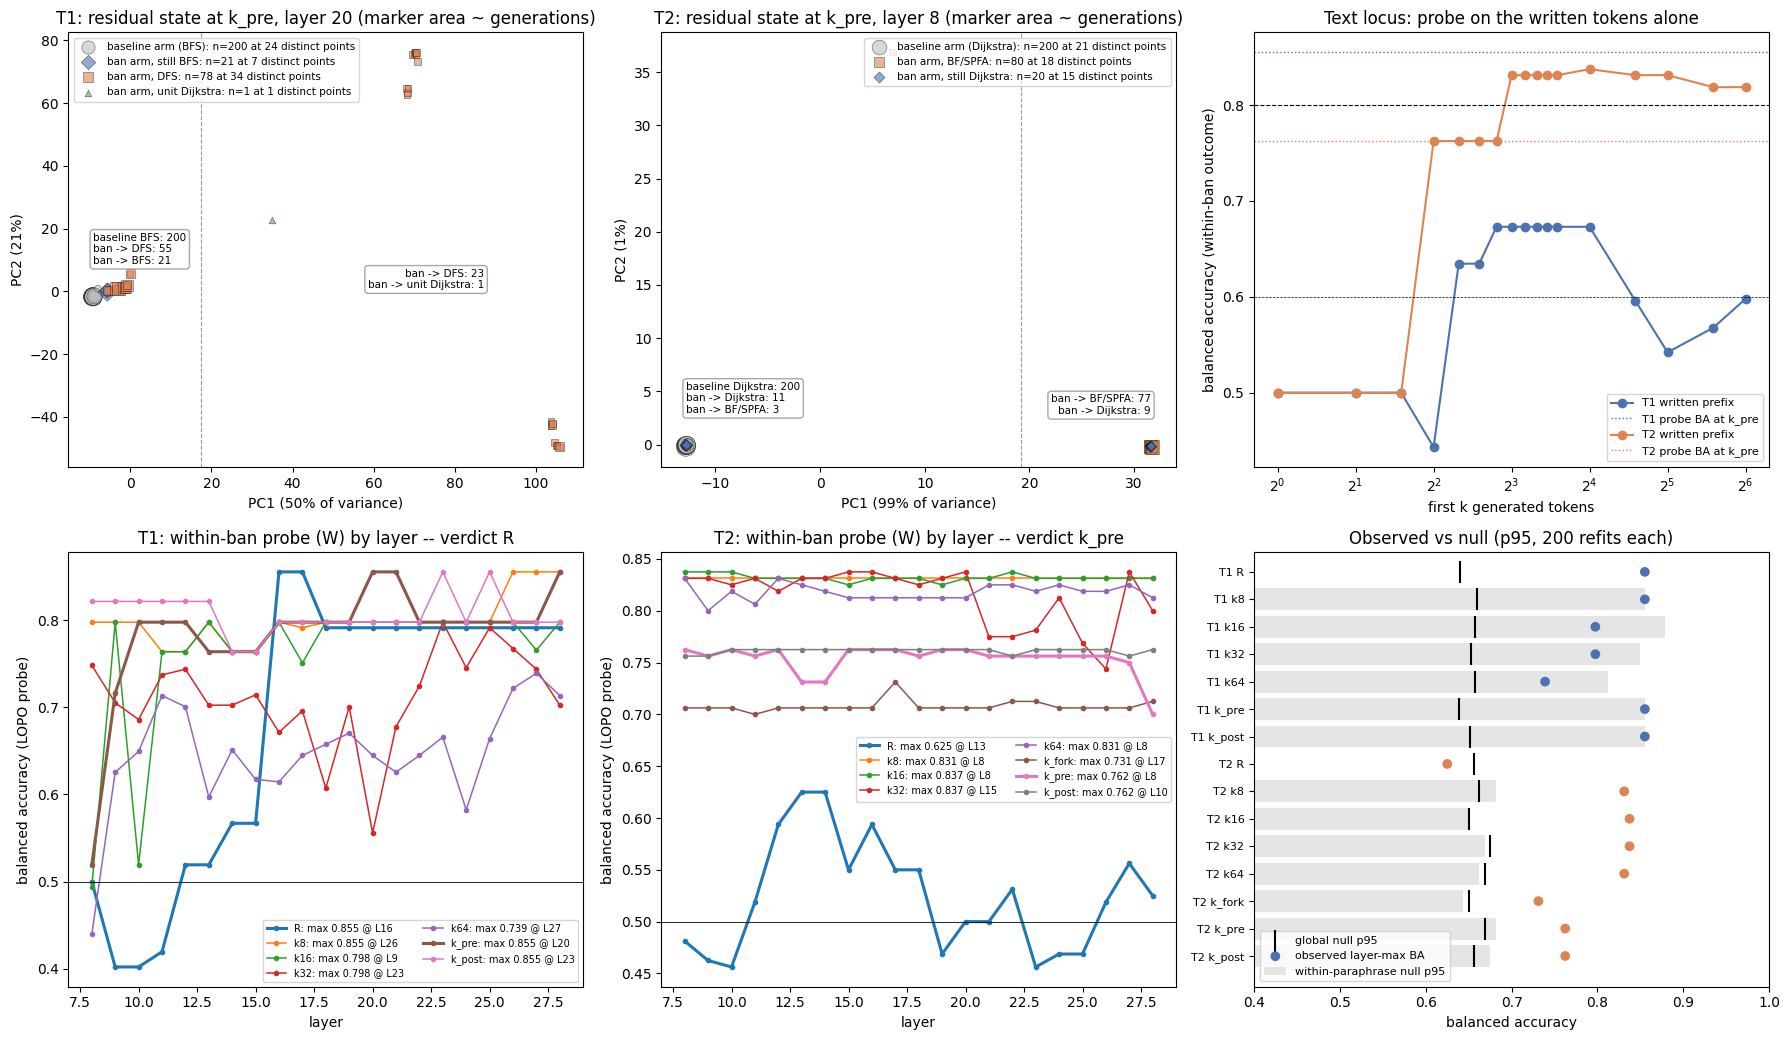

In [20]:
TAG_STYLE = {"baseline:BFS": ("#bdbdbd", "o", "baseline arm (BFS)", "baseline BFS"),
             "ban:BFS": ("#4C72B0", "D", "ban arm, still BFS", "ban -> BFS"),
             "ban:DFS": ("#DD8452", "s", "ban arm, DFS", "ban -> DFS"),
             "ban:unit_dijkstra": ("#55A868", "^", "ban arm, unit Dijkstra", "ban -> unit Dijkstra"),
             "baseline:dijkstra": ("#bdbdbd", "o", "baseline arm (Dijkstra)", "baseline Dijkstra"),
             "ban:dijkstra": ("#4C72B0", "D", "ban arm, still Dijkstra", "ban -> Dijkstra"),
             "ban:bellman_ford_spfa": ("#DD8452", "s", "ban arm, BF/SPFA", "ban -> BF/SPFA")}
fig, axes = plt.subplots(2, 3, figsize=(18, 10.5))

# (top left, top middle) the residual stream at k_pre, projected on its first two principal components.
# Generations that wrote the same prefix share the same state, so identical points are drawn once, area ~ count.
for ax, (t, view) in zip(axes[0, :2], (("T1", "k_pre|L20"), ("T2", "k_pre|L8"))):
    pv = loc["tasks"][t]["pca_views"][view]
    x, y, tag = np.asarray(pv["x"]), np.asarray(pv["y"]), np.asarray(pv["tag"])
    for tg in sorted(set(tag), key=lambda s: (s.startswith("ban"), s)):
        m = tag == tg
        pts, cnt = np.unique(np.c_[x[m], y[m]], axis=0, return_counts=True)
        color, marker, name, _ = TAG_STYLE.get(tg, ("k", "x", tg, tg))
        ax.scatter(pts[:, 0], pts[:, 1], s=14 + 9 * cnt, marker=marker, facecolor=color, edgecolor="k",
                   linewidth=0.4, alpha=0.6, label=f"{name}: n={m.sum()} at {len(pts)} distinct points")
    # split at the widest gap along PC1 and count which generations sit on each side
    xs = np.unique(x)
    cut = xs[np.argmax(np.diff(xs))] + np.diff(xs).max() / 2
    ax.axvline(cut, color="0.6", ls="--", lw=0.8)
    for side in (x < cut, x >= cut):
        counts = pd.Series(tag[side]).value_counts()
        mx, my = np.median(x[side]), np.median(y[side])
        ax.annotate("\n".join(f"{TAG_STYLE.get(tg, ('', '', tg, tg))[3]}: {n}" for tg, n in counts.items()), (mx, my),
                    xytext=(0, 22), textcoords="offset points", ha="left" if mx < cut else "right", va="bottom",
                    fontsize=7.5, bbox=dict(boxstyle="round", fc="white", ec="0.6", alpha=0.85))
    ax.set_xlabel(f"PC1 ({pv['explained'][0]:.0%} of variance)")
    ax.set_ylabel(f"PC2 ({pv['explained'][1]:.0%})")
    ax.set_title(f"{t}: residual state at k_pre, layer {pv['layer']} (marker area ~ generations)")
    ax.legend(fontsize=7.5, loc="upper right" if t == "T2" else "upper left")

# (top right) the written-text control: how early does the text itself give the algorithm away?
ax = axes[0, 2]
for t, color in (("T1", "#4C72B0"), ("T2", "#DD8452")):
    curve = lsec["tasks"][t]["text_locus_curve"]
    ks = sorted(int(k) for k in curve)
    ax.plot(ks, [curve[str(k)] for k in ks], marker="o", color=color, label=f"{t} written prefix")
    ax.axhline(lsec["tasks"][t]["layer_max_table"]["k_pre"]["layer_max_BA"], color=color, ls=":", lw=1,
               label=f"{t} probe BA at k_pre")
ax.axhline(0.8, color="k", ls="--", lw=0.8)
ax.axhline(0.6, color="k", ls="--", lw=0.5)
ax.set_xscale("log", base=2)
ax.set_xlabel("first k generated tokens")
ax.set_ylabel("balanced accuracy (within-ban outcome)")
ax.set_title("Text locus: probe on the written tokens alone")
ax.legend(fontsize=8)

# (bottom left, bottom middle) probe BA per layer at every saved position
for ax, t in zip(axes[1, :2], ("T1", "T2")):
    for p, pr in loc["tasks"][t]["contrasts"]["W"]["positions"].items():
        ax.plot(pr["layers"], pr["BA"], marker=".", lw=2.2 if p in ("R", "k_pre") else 1.1,
                label=f"{p}: max {pr['layer_max_BA']:.3f} @ L{pr['L_star']}")
    ax.axhline(0.5, color="k", lw=0.6)
    ax.set_xlabel("layer")
    ax.set_ylabel("balanced accuracy (LOPO probe)")
    ax.set_title(f"{t}: within-ban probe (W) by layer -- verdict {lsec['tasks'][t]['mechanical_locus']}")
    ax.legend(fontsize=7, ncol=2)

# (bottom right) layer-max BA against the two family-wise nulls
ax = axes[1, 2]
rows = [(t, p, r) for t in ("T1", "T2") for p, r in lsec["tasks"][t]["layer_max_table"].items()]
yy = np.arange(len(rows))
num = lambda v: np.nan if v is None else v
ax.barh(yy, [num(r["null_within_p95"]) for _, _, r in rows], color="#e5e5e5", label="within-paraphrase null p95")
ax.scatter([num(r["null_global_p95"]) for _, _, r in rows], yy, marker="|", s=250, color="k", label="global null p95")
ax.scatter([r["layer_max_BA"] for _, _, r in rows], yy, color=["#4C72B0" if t == "T1" else "#DD8452" for t, _, _ in rows],
           zorder=3, label="observed layer-max BA")
ax.set_yticks(yy, [f"{t} {p}" for t, p, _ in rows], fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("balanced accuracy")
ax.set_title("Observed vs null (p95, 200 refits each)")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

## Results 3: behaviour, knobs and geometry

**Top row.**
- **What the model writes.** Algorithm shares among the correct programs under each curated perturbation (one bar per
  condition row). On T2, almost every row that moves off Dijkstra moves to BF/SPFA: the ban, the semantic seed,
  random steering, the base model. Only gen-then-select, which deliberately keeps diverse samples, adds a sizeable
  Floyd–Warshall share.
- **Knob table.** Rarefied Hill-1 against pass cost; the shaded box is the target (Hill ≥ 2 at < 20 points).
  Temperature rows sit at Hill ≈ 1.

**Bottom row.**
- **Geometry.** `share_nearest` over the 1000 paraphrase subsamples, for each geometry setting in the subset. On T2,
  Floyd–Warshall is always nearest to Dijkstra, yet the model never substitutes it.
- **Distances.** The rightmost panel is the Dijkstra row of exp2's T2 geodesic distance matrix, reproduced exactly.
  The realised substitute, BF/SPFA, is not the nearest.

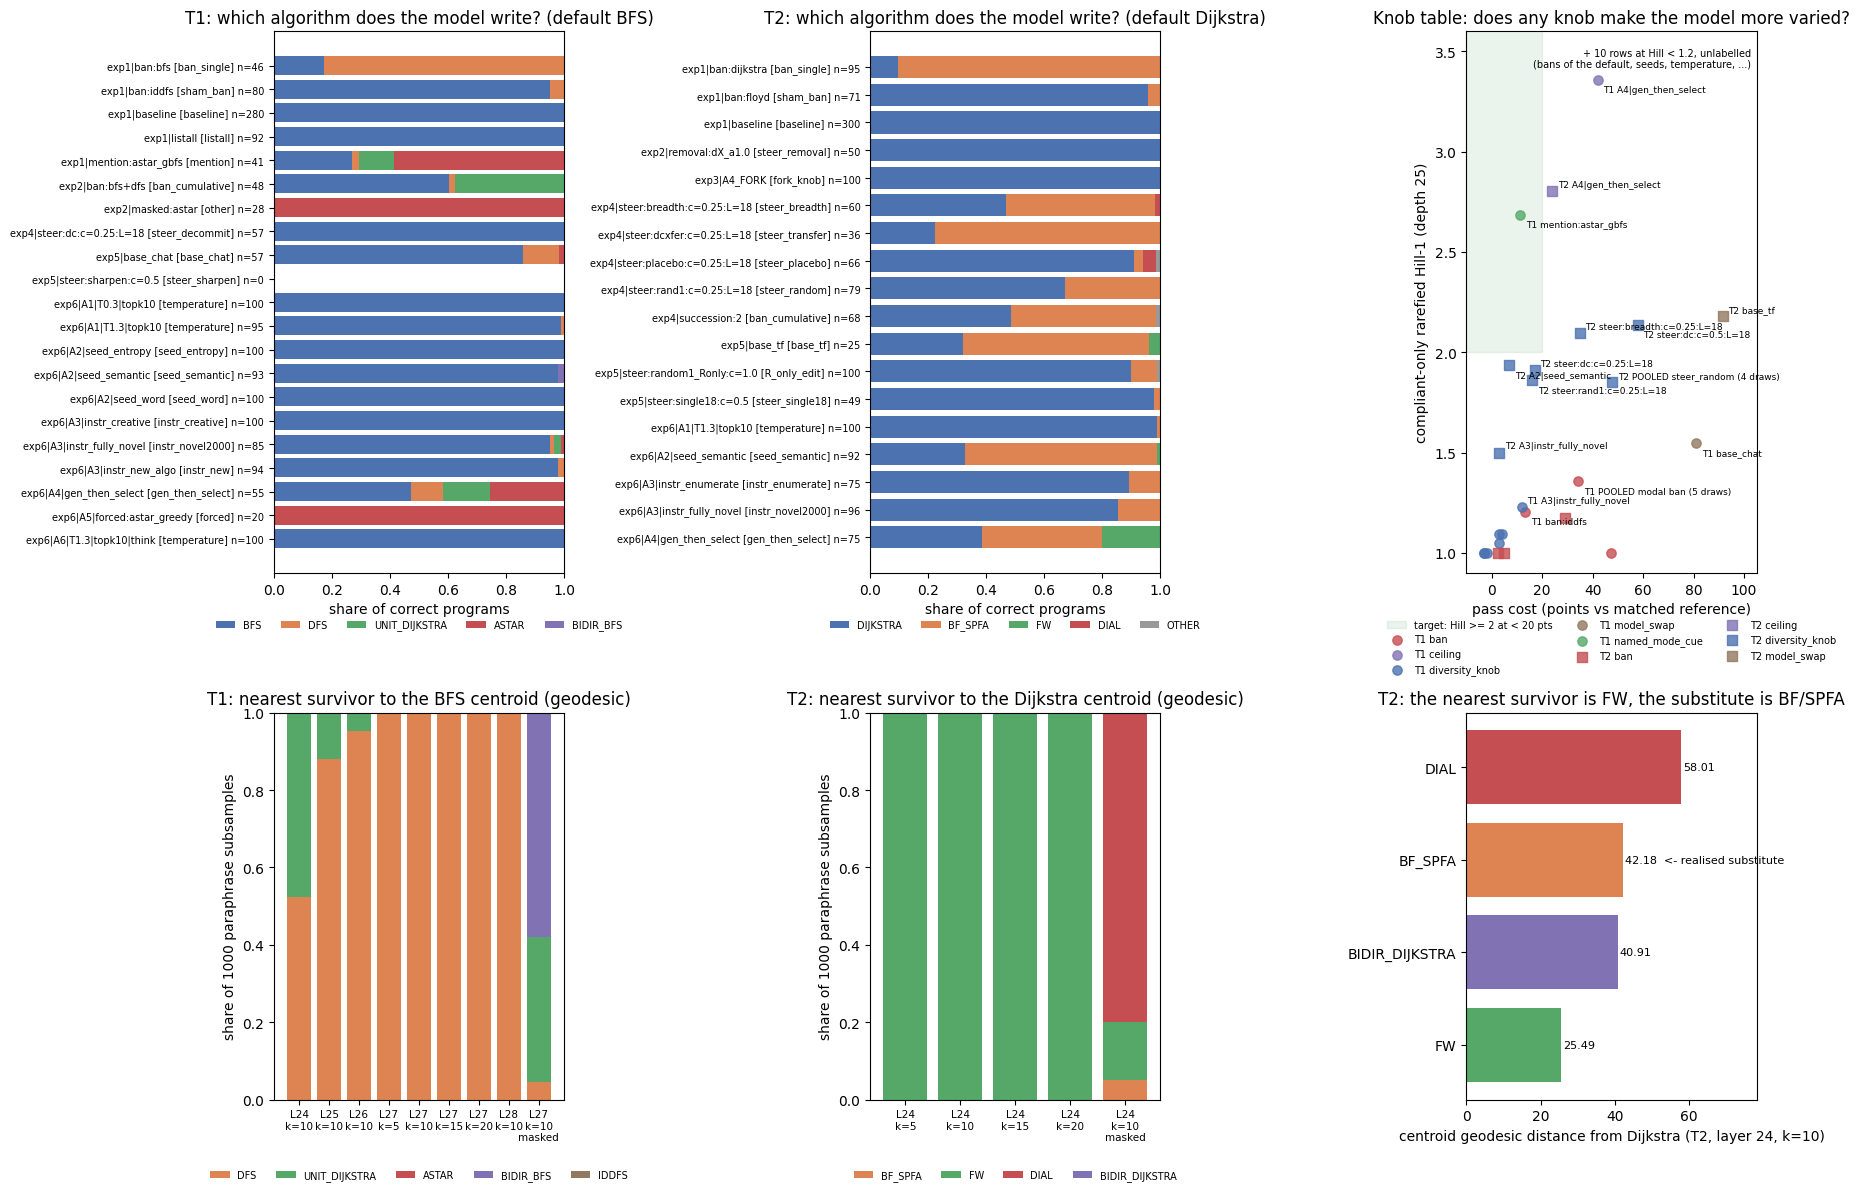

In [21]:
ALGO_COLORS = {"BFS": "#4C72B0", "DIJKSTRA": "#4C72B0", "DFS": "#DD8452", "BF_SPFA": "#DD8452",
               "UNIT_DIJKSTRA": "#55A868", "FW": "#55A868", "ASTAR": "#C44E52", "DIAL": "#C44E52",
               "BIDIR_BFS": "#8172B3", "BIDIR_DIJKSTRA": "#8172B3", "IDDFS": "#937860", "DAG_DP": "#937860", "OTHER": "#999999"}
ALGO_ORDER = list(ALGO_COLORS)
fig, axes = plt.subplots(2, 3, figsize=(18, 12), gridspec_kw={"height_ratios": [1.4, 1]})

# (top left, top middle) composition of the correct programs, one bar per perturbation row
for ax, t in zip(axes[0, :2], ("T1", "T2")):
    rows = pt[pt.task == t]
    if rows.empty:
        ax.text(0.5, 0.5, f"no {t} rows at this config", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        continue
    comps = [json.loads(c) if isinstance(c, str) else {} for c in rows.composition_correct]
    algos = sorted({a for c in comps for a in c}, key=lambda a: ALGO_ORDER.index(a) if a in ALGO_ORDER else 99)
    left = np.zeros(len(rows))
    for a in algos:
        share = np.array([c.get(a, 0) / max(sum(c.values()), 1) for c in comps])
        ax.barh(np.arange(len(rows)), share, left=left, color=ALGO_COLORS.get(a, "#999999"), label=a)
        left += share
    ax.set_yticks(np.arange(len(rows)), [f"{e}|{c} [{ty}] n={n}" for e, c, ty, n in
                                         zip(rows.experiment, rows.condition, rows.type, rows.correct)], fontsize=7)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of correct programs")
    ax.set_title(f"{t}: which algorithm does the model write? (default {'BFS' if t == 'T1' else 'Dijkstra'})")
    ax.legend(fontsize=7, ncol=len(algos), loc="upper center", bbox_to_anchor=(0.5, -0.07), frameon=False)

# (top right) the one-statistic knob table: diversity vs pass-rate cost
ax = axes[0, 2]
CLASS_COLORS = {"diversity_knob": "#4C72B0", "ban": "#C44E52", "named_mode_cue": "#55A868", "ceiling": "#8172B3",
                "model_swap": "#937860"}
k = kt.dropna(subset=["hill1_rarefied"])
xmin = min(-10.0, float(k.pass_points.min()) - 3) if len(k) else -10.0
ax.add_patch(plt.Rectangle((xmin, 2.0), 20 - xmin, 2.0, color="#55A868", alpha=0.12, label="target: Hill >= 2 at < 20 pts"))
for t, marker in (("T1", "o"), ("T2", "s")):
    s = k[k.task == t]
    for cls, g in s.groupby("knob_class"):
        ax.scatter(g.pass_points, g.hill1_rarefied, marker=marker, s=45, color=CLASS_COLORS.get(cls, "k"),
                   alpha=0.8, label=f"{t} {cls}")
for i, (_, r) in enumerate(k[k.hill1_rarefied >= 1.2].sort_values("hill1_rarefied").iterrows()):
    ax.annotate(f"{r.task} {r.knob.split(':', 1)[-1]}", (r.pass_points, r.hill1_rarefied), fontsize=6.5,
                xytext=(4, 3 if i % 2 else -9), textcoords="offset points")
n_one = int((k.hill1_rarefied < 1.2).sum())
ax.text(0.98, 0.97, f"+ {n_one} rows at Hill < 1.2, unlabelled\n(bans of the default, seeds, temperature, ...)",
        fontsize=7, ha="right", va="top", transform=ax.transAxes)
ax.set_xlim(xmin, 105)
ax.set_ylim(0.9, 3.6)
ax.set_xlabel("pass cost (points vs matched reference)")
ax.set_ylabel("compliant-only rarefied Hill-1 (depth 25)")
ax.set_title("Knob table: does any knob make the model more varied?")
ax.legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.07), frameon=False)

# (bottom left, bottom middle) geometry: which survivor is nearest to the default's centroid, over 1000 subsamples
for ax, t in zip(axes[1, :2], ("t1", "t2")):
    g = sorted((c for c in geo["grid"] if c["task"] == t), key=lambda c: (c["kind"] != "forced", c["layer"], c["k"]))
    if not g:
        ax.text(0.5, 0.5, f"no {t.upper()} geometry cells at this config", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        continue
    names = sorted({a for c in g for a in c["share_nearest"]}, key=lambda a: ALGO_ORDER.index(a) if a in ALGO_ORDER else 99)
    bottom = np.zeros(len(g))
    for a in names:
        share = np.array([c["share_nearest"].get(a, 0.0) for c in g])
        ax.bar(np.arange(len(g)), share, bottom=bottom, color=ALGO_COLORS.get(a, "#999999"), label=a)
        bottom += share
    ax.set_xticks(np.arange(len(g)), [f"L{c['layer']}\nk={c['k']}" + ("\nmasked" if c["kind"] == "masked" else "")
                                      for c in g], fontsize=7.5)
    ax.set_ylabel("share of 1000 paraphrase subsamples")
    ax.set_title(f"{t.upper()}: nearest survivor to the {'BFS' if t == 't1' else 'Dijkstra'} centroid (geodesic)")
    ax.legend(fontsize=7, ncol=len(names), loc="upper center", bbox_to_anchor=(0.5, -0.16), frameon=False)

# (bottom right) exp2's T2 Dijkstra row, reproduced: geodesic distance from Dijkstra to every survivor
ax = axes[1, 2]
row = gsec["sensitivity_matrix_T2_dijkstra_row"]
names = sorted(row, key=row.get)
ax.barh(names, [row[a] for a in names], color=[ALGO_COLORS.get(a, "#999999") for a in names])
for i, a in enumerate(names):
    ax.text(row[a] + 0.5, i, f"{row[a]:.2f}" + ("  <- realised substitute" if a == "BF_SPFA" else ""), va="center", fontsize=8)
ax.set_xlim(0, max(row.values()) * 1.35)
ax.set_xlabel("centroid geodesic distance from Dijkstra (T2, layer 24, k=10)")
ax.set_title("T2: the nearest survivor is FW, the substitute is BF/SPFA")
plt.tight_layout()
plt.show()

## Takeaways, and how to run the full audit

- **Temperature is not the creativity knob.** The temperature rows cover T = 0.3–1.3, top-k 10 vs top-p 0.95, with
  and without thinking. All of them sit at Hill ≈ 1.00–1.05, and in every one at least 98% of the correct programs
  use the default algorithm.
- **Context seeds and "invent something fully novel" do not produce new algorithms.**
  - exp6's entropy seed `seed=d32qxk4nt43` and word seed `seed=(horse chair roof love)` change nothing: 100 of 100
    programs keep the default on both tasks.
  - The semantic seed does move T2 off Dijkstra (61 of 92 correct programs), but onto the runner-up BF/SPFA, not
    onto anything new.
  - The 2000-word "fully novel algorithm" instruction moves 14 of 96 correct T2 programs, again to BF/SPFA.
  - No diversity knob or ban reaches Hill ≥ 2 at < 20 pass points on either task.
- **Bans substitute rather than subtract.**
  - Ban the default and the model writes its runner-up: BF/SPFA in 272 of 272 compliant T2 programs across 5 draws,
    DFS in 116 of 128 on T1.
  - 2 of the 9 sham bans of algorithms the model never wrote still promote the runner-up.
- **When is the algorithm decided?**
  - On T1, the state at the end of the prompt already predicts the within-ban outcome (BA 0.855). That is
    paraphrase-level signal: some paraphrases lead to DFS more often than others. No generated position adds
    sample-specific information beyond the within-paraphrase null.
  - On T2, the best generated position, `k_pre`, is a post-commit readout: the written prefix alone gives BA 0.756
    against the state's 0.762.
  - The fork is at generated token 3 (`import heapq` vs `from collections import deque`). States k = 1..3 are the
    next round's extraction target.
- **Geometry** is consistent with both geodesic proximity and typicality, and these events cannot separate them. On
  T2 the nearest neighbour is Floyd–Warshall, not BF/SPFA.

**Full run.**
1. Clone the repository and `cd` into the evaluation folder.
2. `uv pip install -r requirements.txt`.
3. Point `ITER1_ROOT` at the six iteration-1 experiment folders.
4. Run `python eval.py --rerun`: about 16 minutes with a GPU.

To push more rows through this notebook, rebuild `mini_demo_data.json` with `make_mini_demo_data.py` and raise the
config values. The original run used 249 / 183 / 903 / 56 rows.